# Proyecto: clasificación de caracteres Kuzushiji

Notebook reproducible para **Kuzushiji-MNIST (KMNIST)**: 70 000 imágenes en escala de grises de 28×28, 10 clases. Se comparan un baseline, MLP, CNN y pipeline secuencial; se explora un VAE y se reserva el conjunto oficial de prueba para una única evaluación final.

**Métrica principal:** F1-macro, para ponderar por igual cada clase. También se informa accuracy. La división train/dev se hará de forma estratificada sobre el train oficial. No se usarán flips en las aumentaciones, porque pueden alterar la orientación de los caracteres.

| Sección | Etapa del trabajo |
|---|---|
| 1. Entorno y dependencias | Etapa 1: EDA y baseline |
| 2. Estructura del experimento | Etapa 2: análisis de errores y MLP |
| 3. Función/modelos principales | Etapa 3: CNN y pipeline |
| 4. Validaciones | Etapa 4: VAE y pruebas de invariantes |
| 5. Resultados | Etapa 5: comparación, test final y ética |

Ejecutar las celdas en orden. La descarga inicial requiere conexión a Internet y las épocas se pueden ajustar en la configuración.

# 1. Configurar el entorno y dependencias
## Etapa 1: análisis exploratorio, partición y baseline

Dependencias: `torch`, `torchvision`, `scikit-learn`, `pandas`, `numpy` y `matplotlib`. Instalarlas en el entorno/kernel seleccionado si falta alguna (por ejemplo, `python -m pip install torch torchvision scikit-learn pandas matplotlib`). Se carga KMNIST desde torchvision. En esta etapa solo se inspecciona y divide el conjunto oficial de entrenamiento; el conjunto oficial de test queda reservado.

In [1]:
import random
import ssl
import time
import warnings

import certifi
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
MLP_EPOCHS = 8
CNN_EPOCHS = 6
VAE_EPOCHS = 6
DEV_SIZE = 0.15
NUM_WORKERS = 0  # Funciona también en Windows y notebooks.
DATA_DIR = "./data"

# Usa un bundle CA confiable para descargas HTTPS redirigidas desde torchvision.
ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__} | dispositivo: {device}")

PyTorch: 2.14.1+cpu | dispositivo: cpu


In [20]:
# Descarga solo el split oficial de entrenamiento. No abrir el split test todavía.
raw_train = datasets.KMNIST(root=DATA_DIR, train=True, download=True)
# X_all contiene las imágenes: una matriz de 28x28 píxeles por ejemplo, con intensidades 0-255.
X_all = raw_train.data.numpy()
# y_all contiene la clase correcta (etiqueta objetivo) de cada imagen, como un ID entero de 0 a 9.
y_all = raw_train.targets.numpy()
# class_names traduce cada ID de clase a su nombre legible, por ejemplo y_all[i] -> class_names[y_all[i]].
class_names = list(raw_train.classes)

print(f"X: {X_all.shape}, dtype={X_all.dtype}, rango=[{X_all.min()}, {X_all.max()}]")
print(f"y: {y_all.shape}, dtype={y_all.dtype}, clases={len(class_names)}")
print(f"Valores faltantes en X/y: {np.isnan(X_all).sum()} / {pd.isna(y_all).sum()}")
print(f"Memoria X: {X_all.nbytes / (1024 ** 2):.1f} MiB")

class_counts = pd.Series(y_all).value_counts().sort_index()
class_summary = pd.DataFrame({
    "clase_id": np.arange(len(class_names)),
    "etiqueta": class_names,
    "cantidad_imagenes": class_counts.values,
    "porcentaje": 100 * class_counts.values / len(y_all),
})
display(class_summary)

X: (60000, 28, 28), dtype=uint8, rango=[0, 255]
y: (60000,), dtype=int64, clases=10
Valores faltantes en X/y: 0 / 0
Memoria X: 44.9 MiB


,clase_id,etiqueta,cantidad_imagenes,porcentaje
0,0,o,6000,10.0
1,1,ki,6000,10.0
2,2,su,6000,10.0
3,3,tsu,6000,10.0
4,4,na,6000,10.0
5,5,ha,6000,10.0
6,6,ma,6000,10.0
7,7,ya,6000,10.0
8,8,re,6000,10.0
9,9,wo,6000,10.0


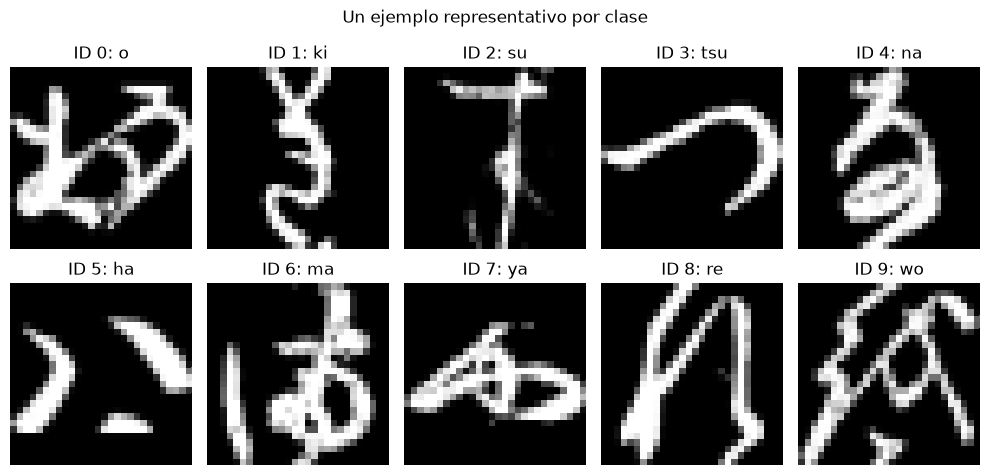

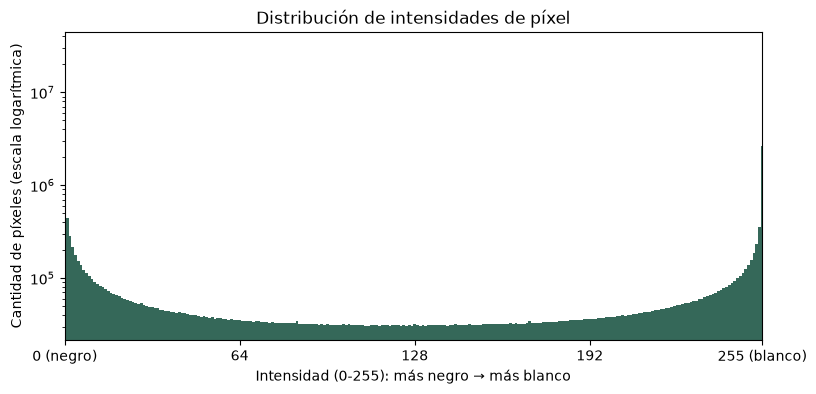

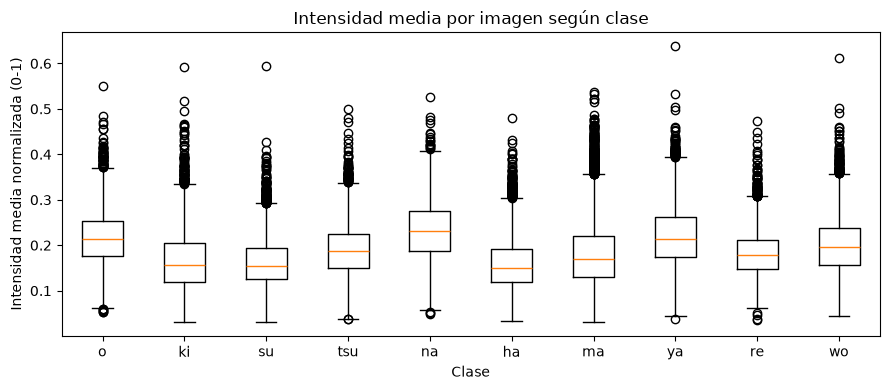

Atípicos estadísticos según 1.5×IQR; no implica que sean imágenes incorrectas.


,clase,limite_inferior,limite_superior,cantidad_atipicos,min_atipico,max_atipico,ejemplos (índice: brillo)
0,o,0.0605,0.3698,65,0.0527,0.5501,25741: 0.053; 11281: 0.054; 42890: 0.056; 3736...
1,ki,-0.0118,0.3345,89,0.3355,0.5922,49168: 0.336; 56775: 0.336; 9196: 0.336; 11904...
2,su,0.0271,0.2924,114,0.2927,0.5953,28339: 0.293; 20229: 0.293; 57162: 0.293; 5301...
3,tsu,0.0382,0.3383,62,0.0371,0.4997,59037: 0.037; 8912: 0.038; 22121: 0.338; 47507...
4,na,0.0557,0.4085,20,0.0489,0.5258,10153: 0.049; 21468: 0.051; 56837: 0.054; 5809...
5,ha,0.0067,0.3041,117,0.3049,0.4804,48595: 0.305; 11691: 0.305; 18287: 0.305; 5883...
6,ma,-0.0045,0.3566,263,0.3567,0.5381,50805: 0.357; 2144: 0.357; 14248: 0.357; 17182...
7,ya,0.0415,0.3944,61,0.0372,0.6381,4287: 0.037; 34442: 0.395; 39503: 0.395; 17685...
8,re,0.0517,0.3077,77,0.0359,0.4744,53144: 0.036; 7360: 0.038; 2414: 0.048; 46311:...
9,wo,0.0366,0.3579,84,0.3584,0.6130,18070: 0.358; 55079: 0.359; 82: 0.359; 21889: ...


,train,dev,train_%,dev_%
0,5100,900,10.0,10.0
1,5100,900,10.0,10.0
2,5100,900,10.0,10.0
3,5100,900,10.0,10.0
4,5100,900,10.0,10.0
5,5100,900,10.0,10.0
6,5100,900,10.0,10.0
7,5100,900,10.0,10.0
8,5100,900,10.0,10.0
9,5100,900,10.0,10.0


In [27]:
# Gráfico 1: un ejemplo por clase para comparar sus formas y similitudes.
representative_ids = [np.flatnonzero(y_all == class_id)[0] for class_id in range(len(class_names))]
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for class_id, axis in enumerate(axes.flat):
    sample_id = representative_ids[class_id]
    axis.imshow(X_all[sample_id], cmap="gray")
    axis.set_title(f"ID {class_id}: {class_names[class_id]}")
    axis.axis("off")
fig.suptitle("Un ejemplo representativo por clase")
plt.tight_layout()
plt.show()

# Gráfico 2: distribución de intensidades de píxel (0 = negro, 255 = blanco).
pixel_counts = np.bincount(X_all.ravel(), minlength=256)
plt.figure(figsize=(9, 4))
plt.bar(np.arange(256), pixel_counts, width=1.0, color="#356859")
plt.yscale("log")
plt.title("Distribución de intensidades de píxel")
plt.xlabel("Intensidad (0-255): más negro → más blanco")
plt.ylabel("Cantidad de píxeles (escala logarítmica)")
plt.xlim(0, 255)
plt.xticks([0, 64, 128, 192, 255], ["0 (negro)", "64", "128", "192", "255 (blanco)"])
plt.show()

# Gráfico 3: variabilidad del brillo medio de las imágenes dentro de cada clase.
mean_brightness = X_all.astype(np.float32).mean(axis=(1, 2)) / 255.0
brightness_by_class = [mean_brightness[y_all == class_id] for class_id in range(len(class_names))]
fig, axis = plt.subplots(figsize=(9, 4))
axis.boxplot(brightness_by_class)
axis.set_xticks(np.arange(1, len(class_names) + 1), class_names)
axis.set_title("Intensidad media por imagen según clase")
axis.set_xlabel("Clase")
axis.set_ylabel("Intensidad media normalizada (0-1)")
plt.tight_layout()
plt.show()

# Regla de Tukey: atípico si queda fuera de Q1 - 1.5*IQR o Q3 + 1.5*IQR.
outlier_summary_rows = []
for class_id, class_name in enumerate(class_names):
    class_indices = np.flatnonzero(y_all == class_id)
    class_values = mean_brightness[class_indices]
    first_quartile, third_quartile = np.percentile(class_values, [25, 75])
    interquartile_range = third_quartile - first_quartile
    lower_limit = first_quartile - 1.5 * interquartile_range
    upper_limit = third_quartile + 1.5 * interquartile_range
    outlier_mask = (class_values < lower_limit) | (class_values > upper_limit)
    outlier_indices = class_indices[outlier_mask]
    outlier_values = mean_brightness[outlier_indices]

    if len(outlier_indices):
        ordered_indices = outlier_indices[np.argsort(outlier_values)]
        example_indices = list(dict.fromkeys(
            list(ordered_indices[:3]) + list(ordered_indices[-3:])
        ))
        example_values = "; ".join(
            f"{image_id}: {mean_brightness[image_id]:.3f}" for image_id in example_indices
        )
        minimum_outlier = float(outlier_values.min())
        maximum_outlier = float(outlier_values.max())
    else:
        example_values = "Sin atípicos"
        minimum_outlier = np.nan
        maximum_outlier = np.nan

    outlier_summary_rows.append({
        "clase": class_name,
        "limite_inferior": lower_limit,
        "limite_superior": upper_limit,
        "cantidad_atipicos": len(outlier_indices),
        "min_atipico": minimum_outlier,
        "max_atipico": maximum_outlier,
        "ejemplos (índice: brillo)": example_values,
    })

outlier_summary = pd.DataFrame(outlier_summary_rows)
print("Atípicos estadísticos según 1.5×IQR; no implica que sean imágenes incorrectas.")
display(outlier_summary.round({"limite_inferior": 4, "limite_superior": 4, "min_atipico": 4, "max_atipico": 4}))

# Split aleatorio estratificado: conserva la proporción de las 10 clases.
train_idx, dev_idx = train_test_split(
    np.arange(len(y_all)), test_size=DEV_SIZE, random_state=SEED, stratify=y_all
)
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_dev, y_dev = X_all[dev_idx], y_all[dev_idx]

split_summary = pd.DataFrame({
    "train": np.bincount(y_train, minlength=10),
    "dev": np.bincount(y_dev, minlength=10),
})
split_summary["train_%"] = 100 * split_summary["train"] / len(y_train)
split_summary["dev_%"] = 100 * split_summary["dev"] / len(y_dev)
display(split_summary)
assert set(np.unique(y_train)) == set(np.unique(y_dev))
assert np.max(np.abs(split_summary["train_%"] - split_summary["dev_%"])) < 0.1

# Tensores normalizados compartidos por modelos densos, CNN y VAE.
X_train_t = torch.from_numpy(X_train.copy()).float().unsqueeze(1).div_(255)
X_dev_t = torch.from_numpy(X_dev.copy()).float().unsqueeze(1).div_(255)
y_train_t = torch.from_numpy(y_train.copy()).long()
y_dev_t = torch.from_numpy(y_dev.copy()).long()
train_ds = TensorDataset(X_train_t, y_train_t)
dev_ds = TensorDataset(X_dev_t, y_dev_t)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
dev_loader = DataLoader(dev_ds, batch_size=512, shuffle=False, num_workers=NUM_WORKERS)

# El test oficial se abre únicamente en la última sección.

## Baseline: regresión logística

El aplanado conserva 784 atributos de intensidad por imagen y la escala se transforma a [0, 1]. F1-macro es la métrica de referencia porque promedia el F1 por clase sin que las clases frecuentes dominen; se reporta también accuracy. El baseline se ajusta con train y se compara en Dev, nunca en Test.

In [28]:
results = []
X_train_flat = X_train.reshape(len(X_train), -1).astype(np.float32) / 255.0
X_dev_flat = X_dev.reshape(len(X_dev), -1).astype(np.float32) / 255.0

baseline = LogisticRegression(max_iter=400, solver="lbfgs", C=1.0)
start_time = time.perf_counter()
with warnings.catch_warnings(record=True) as baseline_warnings:
    warnings.simplefilter("always")
    baseline.fit(X_train_flat, y_train)
baseline_seconds = time.perf_counter() - start_time
baseline_dev_pred = baseline.predict(X_dev_flat)
baseline_f1 = f1_score(y_dev, baseline_dev_pred, average="macro")
baseline_acc = accuracy_score(y_dev, baseline_dev_pred)
baseline_params = int(baseline.coef_.size + baseline.intercept_.size)
results.append({
    "modelo": "Regresión logística",
    "arquitectura": "784 entradas → 10 clases (softmax)",
    "parámetros": baseline_params,
    "dev_f1_macro": baseline_f1,
    "dev_accuracy": baseline_acc,
    "test_f1_macro": np.nan,
    "tiempo_seg": baseline_seconds,
})
print(f"Dev F1-macro: {baseline_f1:.4f} | accuracy: {baseline_acc:.4f}")
print(f"Parámetros: {baseline_params:,} | entrenamiento: {baseline_seconds:.1f} s")
if baseline_warnings:
    print("Avisos de entrenamiento:", *[str(item.message) for item in baseline_warnings], sep="\n- ")

Dev F1-macro: 0.8171 | accuracy: 0.8166
Parámetros: 7,850 | entrenamiento: 13.8 s


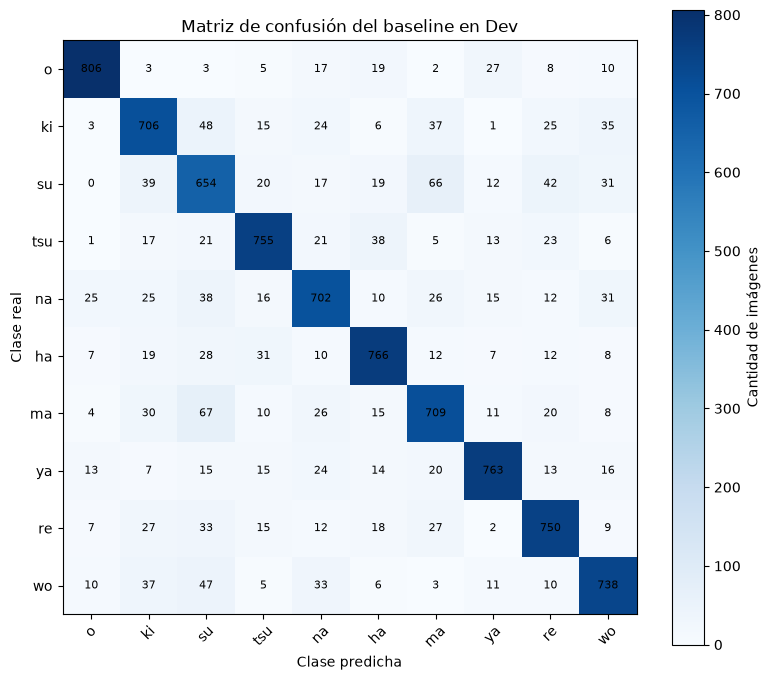

,Métrica,Valor (%)
0,Accuracy,81.66%
1,Precisión macro,81.80%
2,Recall macro,81.66%
3,F1-macro,81.71%


In [31]:
# Matriz de confusión del baseline en Dev: filas = clase real, columnas = predicción.
baseline_cm = confusion_matrix(y_dev, baseline_dev_pred, labels=np.arange(len(class_names)))
fig, axis = plt.subplots(figsize=(8, 7))
image = axis.imshow(baseline_cm, cmap="Blues")
fig.colorbar(image, ax=axis, label="Cantidad de imágenes")
axis.set_title("Matriz de confusión del baseline en Dev")
axis.set_xlabel("Clase predicha")
axis.set_ylabel("Clase real")
axis.set_xticks(np.arange(len(class_names)), class_names, rotation=45)
axis.set_yticks(np.arange(len(class_names)), class_names)
for row_index in range(len(class_names)):
    for column_index in range(len(class_names)):
        axis.text(
            column_index, row_index, baseline_cm[row_index, column_index],
            ha="center", va="center", fontsize=8,
        )
plt.tight_layout()
plt.show()

# Métricas agregadas del baseline calculadas únicamente sobre Dev y mostradas en porcentaje.
baseline_report = classification_report(
    y_dev, baseline_dev_pred, output_dict=True, zero_division=0
)
baseline_metric_table = pd.DataFrame({
    "Métrica": ["Accuracy", "Precisión macro", "Recall macro", "F1-macro"],
    "Valor (%)": [
        100 * accuracy_score(y_dev, baseline_dev_pred),
        100 * baseline_report["macro avg"]["precision"],
        100 * baseline_report["macro avg"]["recall"],
        100 * baseline_report["macro avg"]["f1-score"],
    ],
})
display(baseline_metric_table.style.format({"Valor (%)": "{:.2f}%"}))

# 2. Estructura básica del experimento
## Etapa 2: análisis de errores, MLP y regularización

La tabla siguiente deja 50 errores concretos para revisión manual. Una predicción equivocada por sí sola no permite decidir si el problema es sesgo (modelo demasiado simple), varianza (sobreajuste) o mismatch (diferencia entre datos de entrenamiento y uso esperado); se registra cada caso como pendiente hasta inspeccionar la imagen y el contexto disponible.

Errores disponibles en Dev: 1651; casos seleccionados: 50


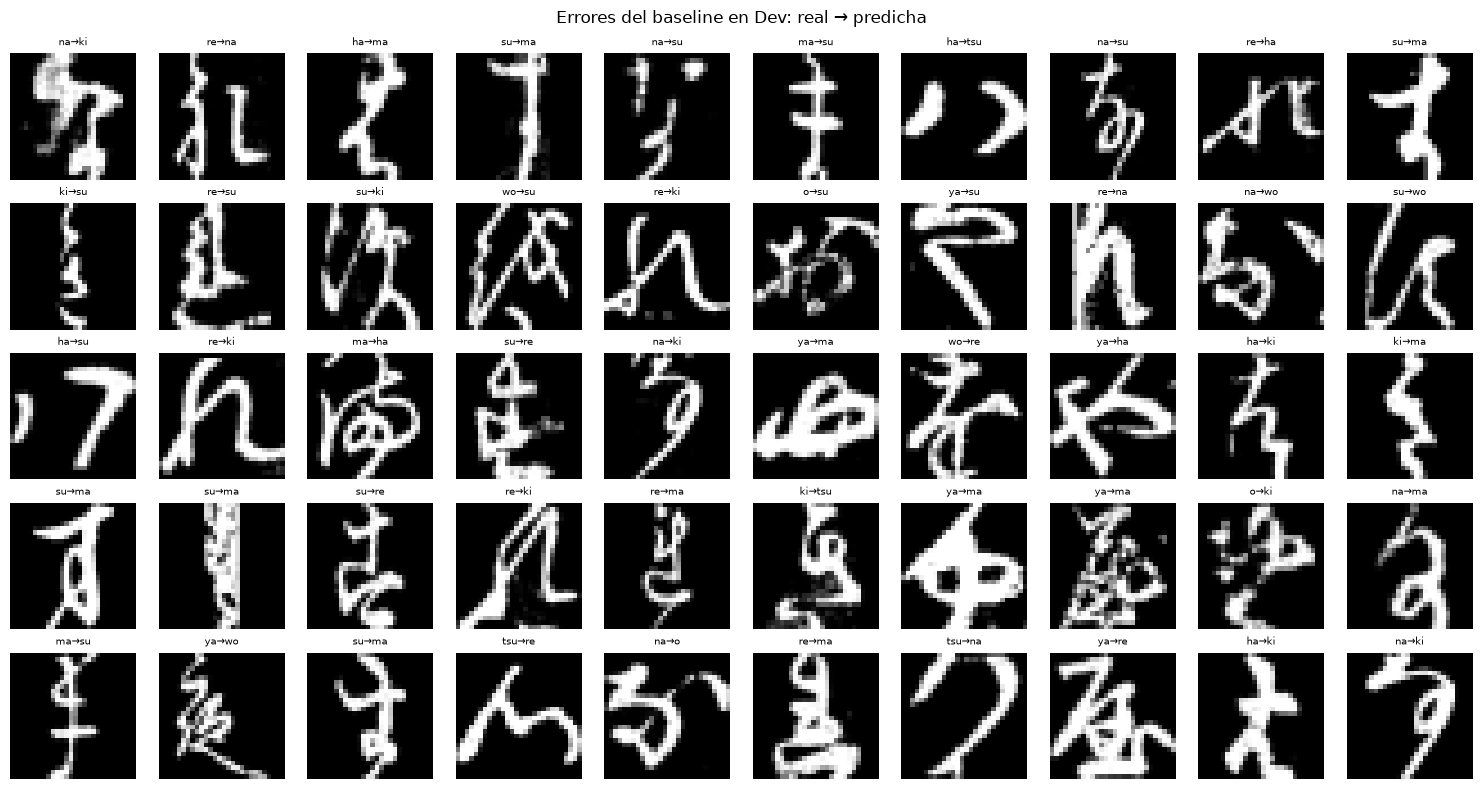

,indice_dev,real_id,real,predicha_id,predicha,causa_manual,observaciones
0,3456,4,na,1,ki,pendiente de revisión,
1,4335,8,re,4,na,pendiente de revisión,
2,3812,5,ha,6,ma,pendiente de revisión,
3,765,2,su,6,ma,pendiente de revisión,
4,7014,4,na,2,su,pendiente de revisión,
5,8717,6,ma,2,su,pendiente de revisión,
6,5607,5,ha,3,tsu,pendiente de revisión,
7,6201,4,na,2,su,pendiente de revisión,
8,2367,8,re,5,ha,pendiente de revisión,
9,3833,2,su,6,ma,pendiente de revisión,


Categorías de revisión sugeridas: sesgo/underfitting, varianza/overfitting, mismatch o ambiguo/no concluyente.


In [7]:
baseline_error_idx = np.flatnonzero(baseline_dev_pred != y_dev)
rng = np.random.default_rng(SEED)
review_idx = rng.choice(baseline_error_idx, size=min(50, len(baseline_error_idx)), replace=False)
error_review = pd.DataFrame({
    "indice_dev": review_idx,
    "real_id": y_dev[review_idx],
    "real": [class_names[label] for label in y_dev[review_idx]],
    "predicha_id": baseline_dev_pred[review_idx],
    "predicha": [class_names[label] for label in baseline_dev_pred[review_idx]],
    "causa_manual": "pendiente de revisión",
    "observaciones": "",
})
print(f"Errores disponibles en Dev: {len(baseline_error_idx)}; casos seleccionados: {len(error_review)}")
fig, axes = plt.subplots(5, 10, figsize=(15, 8))
for axis, dev_i in zip(axes.flat, review_idx):
    axis.imshow(X_dev[dev_i], cmap="gray")
    axis.set_title(f"{class_names[y_dev[dev_i]]}→{class_names[baseline_dev_pred[dev_i]]}", fontsize=7)
    axis.axis("off")
plt.suptitle("Errores del baseline en Dev: real → predicha")
plt.tight_layout()
plt.show()
display(error_review)

print("Categorías de revisión sugeridas: sesgo/underfitting, varianza/overfitting, mismatch o ambiguo/no concluyente.")

### Lectura inicial de los errores

La muestra de 50 imágenes sirve para completar `causa_manual` y `observaciones` tras inspección. Como hipótesis global del baseline, una regresión logística solo separa clases mediante fronteras lineales sobre píxeles: confusiones entre trazos visualmente próximos son compatibles con **sesgo/underfitting** y motivan representaciones no lineales (MLP/CNN). La **varianza/overfitting** no se puede concluir de estos errores de Dev: hay que comparar métricas de train y Dev, como se hace en la sección MLP. Tampoco se demuestra **data mismatch** con una partición aleatoria del mismo origen; harían falta ejemplos del dominio de despliegue. Por eso los 50 renglones no se etiquetan automáticamente.

In [8]:
class MLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 10),
        )

    def forward(self, images):
        return self.layers(images)


def collect_metrics(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    true_labels, predictions = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * len(labels)
            predictions.extend(logits.argmax(dim=1).cpu().numpy())
            true_labels.extend(labels.cpu().numpy())
    return {
        "loss": total_loss / len(loader.dataset),
        "f1": f1_score(true_labels, predictions, average="macro"),
        "accuracy": accuracy_score(true_labels, predictions),
    }


def fit_classifier(model, epochs, weight_decay=0.0, patience=None):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=weight_decay)
    train_eval_size = min(6000, len(train_ds))
    train_eval_idx = np.random.default_rng(SEED).choice(len(train_ds), train_eval_size, replace=False)
    train_eval_loader = DataLoader(
        torch.utils.data.Subset(train_ds, train_eval_idx), batch_size=512,
        shuffle=False, num_workers=NUM_WORKERS,
    )
    history = {"train_loss": [], "dev_loss": [], "train_f1": [], "dev_f1": []}
    best_f1, best_state, stale_epochs = -1.0, None, 0
    start_time = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(labels)

        train_metrics = collect_metrics(model, train_eval_loader, criterion)
        dev_metrics = collect_metrics(model, dev_loader, criterion)
        history["train_loss"].append(running_loss / len(train_ds))
        history["dev_loss"].append(dev_metrics["loss"])
        history["train_f1"].append(train_metrics["f1"])
        history["dev_f1"].append(dev_metrics["f1"])
        print(
            f"Época {epoch + 1:02d}/{epochs} | "
            f"loss train/dev={history['train_loss'][-1]:.3f}/{dev_metrics['loss']:.3f} | "
            f"F1 train-muestra/dev={train_metrics['f1']:.3f}/{dev_metrics['f1']:.3f}"
        )

        if dev_metrics["f1"] > best_f1:
            best_f1 = dev_metrics["f1"]
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            stale_epochs = 0
        else:
            stale_epochs += 1
            if patience is not None and stale_epochs >= patience:
                print("Early stopping: sin mejora de F1-macro en Dev.")
                break

    model.load_state_dict(best_state)
    elapsed = time.perf_counter() - start_time
    final_dev = collect_metrics(model, dev_loader, criterion)
    return model, history, elapsed, final_dev


def plot_history(history, title):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["dev_loss"], label="Dev")
    axes[0].set(title="Loss", xlabel="Época")
    axes[0].legend()
    axes[1].plot(epochs, history["train_f1"], label="Train (muestra)")
    axes[1].plot(epochs, history["dev_f1"], label="Dev")
    axes[1].set(title="F1-macro", xlabel="Época")
    axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

print("MLP: tres capas ocultas (256, 128, 64), ReLU, CrossEntropyLoss y Adam.")

MLP: tres capas ocultas (256, 128, 64), ReLU, CrossEntropyLoss y Adam.


### Entrenamiento de MLP y regularización

Las variantes usan la misma arquitectura y el mismo subconjunto de entrenamiento para que la comparación sea interpretable. La versión regularizada combina Dropout, penalización L2 (`weight_decay`) y Early Stopping según F1-macro de Dev. En CPU se limita por defecto a 15 000 imágenes para los modelos neuronales; cambiar `DEEP_TRAIN_LIMIT` a `None` usa todo train. El baseline logístico ya usó el train completo.

In [9]:
DEEP_TRAIN_LIMIT = 15000  # None para usar las 51 000 imágenes de train.
if DEEP_TRAIN_LIMIT is not None and DEEP_TRAIN_LIMIT < len(train_ds):
    deep_indices = np.random.default_rng(SEED).choice(len(train_ds), DEEP_TRAIN_LIMIT, replace=False)
    train_ds = torch.utils.data.Subset(train_ds, deep_indices)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
print(f"Imágenes para redes neuronales: {len(train_ds):,} de {len(train_idx):,}; Dev: {len(dev_ds):,}.")

Imágenes para redes neuronales: 15,000 de 51,000; Dev: 9,000.


Época 01/8 | loss train/dev=1.018/0.593 | F1 train-muestra/dev=0.831/0.824
Época 02/8 | loss train/dev=0.479/0.449 | F1 train-muestra/dev=0.884/0.864
Época 03/8 | loss train/dev=0.351/0.360 | F1 train-muestra/dev=0.924/0.891
Época 04/8 | loss train/dev=0.274/0.340 | F1 train-muestra/dev=0.938/0.897
Época 05/8 | loss train/dev=0.218/0.304 | F1 train-muestra/dev=0.955/0.910
Época 06/8 | loss train/dev=0.168/0.305 | F1 train-muestra/dev=0.960/0.913
Época 07/8 | loss train/dev=0.133/0.288 | F1 train-muestra/dev=0.975/0.918
Época 08/8 | loss train/dev=0.092/0.282 | F1 train-muestra/dev=0.987/0.922
Época 01/8 | loss train/dev=1.256/0.615 | F1 train-muestra/dev=0.823/0.815
Época 02/8 | loss train/dev=0.595/0.415 | F1 train-muestra/dev=0.889/0.875
Época 03/8 | loss train/dev=0.454/0.357 | F1 train-muestra/dev=0.920/0.894
Época 04/8 | loss train/dev=0.353/0.314 | F1 train-muestra/dev=0.940/0.907
Época 05/8 | loss train/dev=0.292/0.295 | F1 train-muestra/dev=0.951/0.911
Época 06/8 | loss train/d

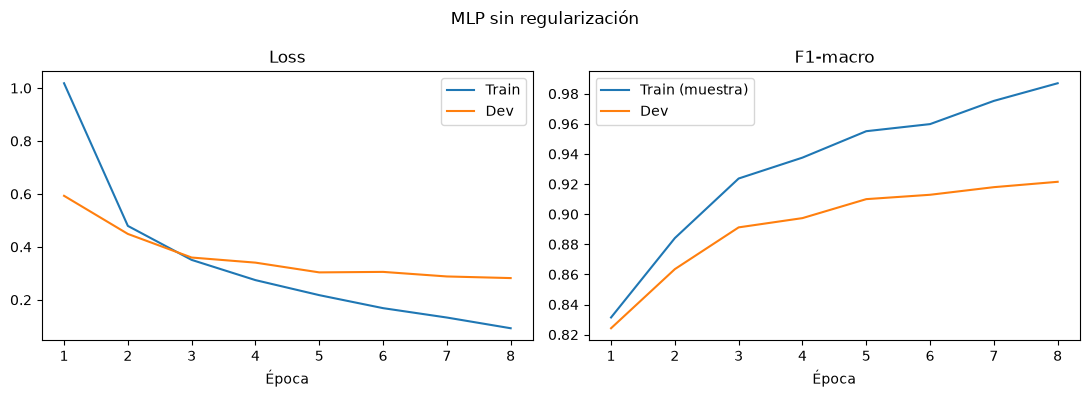

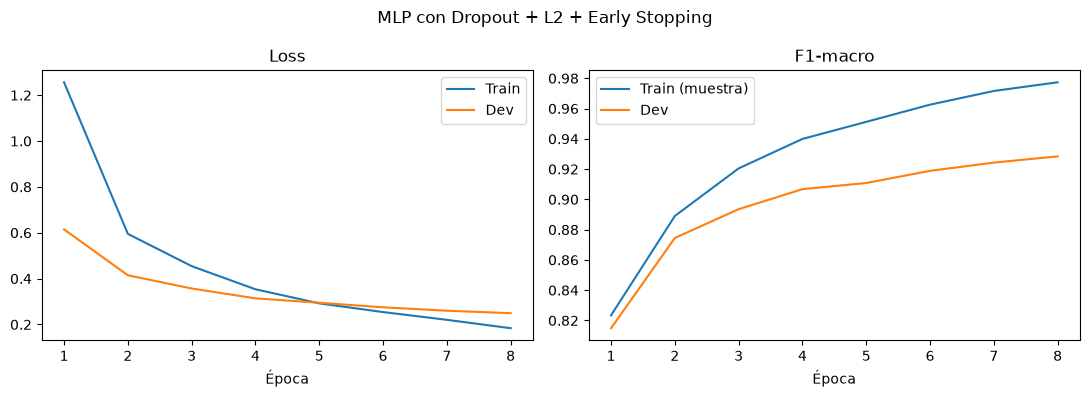

Cambio de F1 vs baseline (MLP regularizada): +0.1113


In [10]:
mlp_plain, history_plain, mlp_plain_seconds, mlp_plain_dev = fit_classifier(
    MLP(dropout=0.0), epochs=MLP_EPOCHS, weight_decay=0.0, patience=None
)
mlp_reg, history_reg, mlp_reg_seconds, mlp_reg_dev = fit_classifier(
    MLP(dropout=0.25), epochs=MLP_EPOCHS, weight_decay=1e-4, patience=3
)

for name, model, history, elapsed, metrics in [
    ("MLP sin regularización", mlp_plain, history_plain, mlp_plain_seconds, mlp_plain_dev),
    ("MLP Dropout + L2 + Early Stopping", mlp_reg, history_reg, mlp_reg_seconds, mlp_reg_dev),
]:
    results.append({
        "modelo": name,
        "arquitectura": "784 → 256 → 128 → 64 → 10",
        "parámetros": count_parameters(model),
        "dev_f1_macro": metrics["f1"],
        "dev_accuracy": metrics["accuracy"],
        "test_f1_macro": np.nan,
        "tiempo_seg": elapsed,
    })
    print(f"{name}: Dev F1-macro={metrics['f1']:.4f}, accuracy={metrics['accuracy']:.4f}, tiempo={elapsed:.1f}s")

plot_history(history_plain, "MLP sin regularización")
plot_history(history_reg, "MLP con Dropout + L2 + Early Stopping")
print(f"Cambio de F1 vs baseline (MLP regularizada): {mlp_reg_dev['f1'] - baseline_f1:+.4f}")

# 3. Función/modelos principales
## Etapa 3: CNN y pipeline secuencial

La CNN usa tres bloques Conv2D + ReLU + MaxPooling. Para la comparación secuencial se reutiliza su extractor entrenado en train, se congelan sus características y se ajusta una regresión logística sobre ellas. La aumentación es una transformación afín moderada (rotación, traslación y zoom); no se espejan los caracteres.

Época 01/6 | loss train/dev=1.918/1.372 | F1 train-muestra/dev=0.555/0.561
Época 02/6 | loss train/dev=1.166/0.845 | F1 train-muestra/dev=0.736/0.742
Época 03/6 | loss train/dev=0.861/0.624 | F1 train-muestra/dev=0.802/0.812
Época 04/6 | loss train/dev=0.713/0.516 | F1 train-muestra/dev=0.840/0.845
Época 05/6 | loss train/dev=0.599/0.452 | F1 train-muestra/dev=0.852/0.861
Época 06/6 | loss train/dev=0.512/0.334 | F1 train-muestra/dev=0.898/0.900


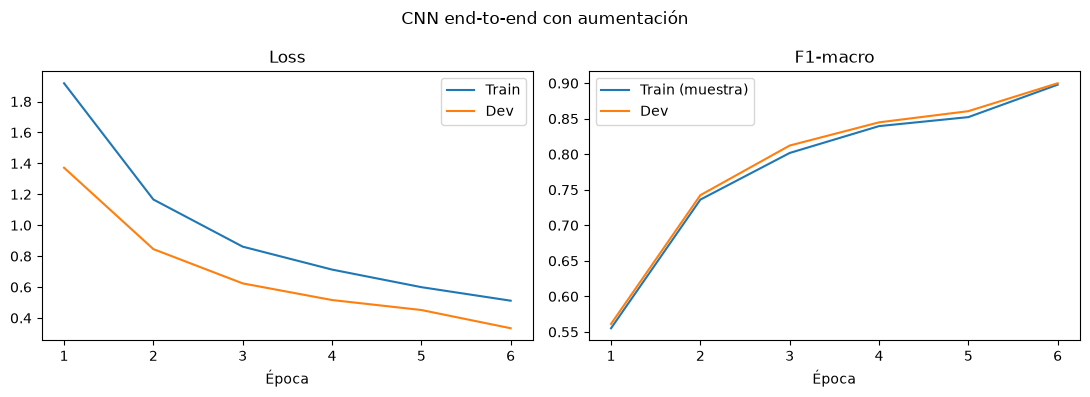

CNN: Dev F1-macro=0.8999, accuracy=0.8992, tiempo=51.8s
Pipeline: Dev F1-macro=0.9349, accuracy=0.9348, tiempo=4.2s
Diagnóstico aproximado en Dev: 476 errores end-to-end corregidos por pipeline; 156 errores nuevos; 431 errores compartidos. La diferencia no identifica causalmente la etapa responsable.
Mejora CNN end-to-end vs MLP regularizada: -0.0285 F1-macro.


In [12]:
class KMNISTAugmented(Dataset):
    def __init__(self, images, labels, indices, transform):
        self.images = images
        self.labels = labels
        self.indices = np.asarray(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        index = int(self.indices[position])
        return self.transform(self.images[index]), self.labels[index]


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
        )
        self.classifier = nn.Linear(128, 10)

    def forward_features(self, images):
        return self.features(images)

    def forward(self, images):
        return self.classifier(self.forward_features(images))


if isinstance(train_ds, torch.utils.data.Subset):
    selected_train_indices = np.asarray(train_ds.indices)
else:
    selected_train_indices = np.arange(len(train_ds))

augmentation = transforms.RandomAffine(degrees=8, translate=(0.08, 0.08), scale=(0.9, 1.1))
augmented_ds = KMNISTAugmented(X_train_t, y_train_t, selected_train_indices, augmentation)
train_loader = DataLoader(augmented_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
cnn, cnn_history, cnn_seconds, cnn_dev = fit_classifier(
    CNN(), epochs=CNN_EPOCHS, weight_decay=1e-4, patience=4
)
plot_history(cnn_history, "CNN end-to-end con aumentación")
results.append({
    "modelo": "CNN end-to-end",
    "arquitectura": "3 bloques Conv/ReLU/MaxPool + clasificador lineal",
    "parámetros": count_parameters(cnn),
    "dev_f1_macro": cnn_dev["f1"],
    "dev_accuracy": cnn_dev["accuracy"],
    "test_f1_macro": np.nan,
    "tiempo_seg": cnn_seconds,
})
print(f"CNN: Dev F1-macro={cnn_dev['f1']:.4f}, accuracy={cnn_dev['accuracy']:.4f}, tiempo={cnn_seconds:.1f}s")

# El extractor se congela y se entrena un clasificador lineal sobre sus vectores.
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)

def extract_cnn_features(model, images, labels):
    loader = DataLoader(TensorDataset(images, labels), batch_size=512, shuffle=False)
    feature_batches = []
    model.eval()
    with torch.no_grad():
        for batch_images, _ in loader:
            feature_batches.append(model.forward_features(batch_images.to(device)).cpu().numpy())
    return np.concatenate(feature_batches)

pipeline_start = time.perf_counter()
train_features = extract_cnn_features(cnn, X_train_t[selected_train_indices], y_train_t[selected_train_indices])
dev_features = extract_cnn_features(cnn, X_dev_t, y_dev_t)
pipeline_scaler = StandardScaler()
train_features_scaled = pipeline_scaler.fit_transform(train_features)
dev_features_scaled = pipeline_scaler.transform(dev_features)
pipeline_classifier = LogisticRegression(max_iter=500, solver="lbfgs", C=1.0)
pipeline_classifier.fit(train_features_scaled, y_train[selected_train_indices])
pipeline_seconds = time.perf_counter() - pipeline_start
pipeline_dev_pred = pipeline_classifier.predict(dev_features_scaled)
pipeline_f1 = f1_score(y_dev, pipeline_dev_pred, average="macro")
pipeline_acc = accuracy_score(y_dev, pipeline_dev_pred)
results.append({
    "modelo": "CNN congelada + LogisticRegression",
    "arquitectura": "CNN extractor 128-D congelado + softmax lineal",
    "parámetros": count_parameters(cnn) + pipeline_classifier.coef_.size + pipeline_classifier.intercept_.size,
    "dev_f1_macro": pipeline_f1,
    "dev_accuracy": pipeline_acc,
    "test_f1_macro": np.nan,
    "tiempo_seg": pipeline_seconds,
})
print(f"Pipeline: Dev F1-macro={pipeline_f1:.4f}, accuracy={pipeline_acc:.4f}, tiempo={pipeline_seconds:.1f}s")

cnn.eval()
with torch.no_grad():
    logits_dev = []
    for batch_images, _ in dev_loader:
        logits_dev.append(cnn(batch_images.to(device)).argmax(dim=1).cpu().numpy())
    end_to_end_pred = np.concatenate(logits_dev)

end_to_end_errors = end_to_end_pred != y_dev
pipeline_errors = pipeline_dev_pred != y_dev
rescued_by_pipeline = int(np.sum(end_to_end_errors & ~pipeline_errors))
new_pipeline_errors = int(np.sum(~end_to_end_errors & pipeline_errors))
shared_errors = int(np.sum(end_to_end_errors & pipeline_errors))
print(
    f"Diagnóstico aproximado en Dev: {rescued_by_pipeline} errores end-to-end corregidos por pipeline; "
    f"{new_pipeline_errors} errores nuevos; {shared_errors} errores compartidos. "
    "La diferencia no identifica causalmente la etapa responsable."
)
print(f"Mejora CNN end-to-end vs MLP regularizada: {cnn_dev['f1'] - mlp_reg_dev['f1']:+.4f} F1-macro.")

# 4. Validaciones y modelo generativo
## Etapa 4: VAE convolucional y espacio latente

Se elige un VAE porque permite visualizar una representación probabilística continua y reconstrucciones, con entrenamiento más estable y sencillo de evaluar que una GAN pequeña en CPU. El latente tiene dimensión 2 para facilitar su inspección; el objetivo combina BCE de reconstrucción y divergencia KL. Se reporta MSE de reconstrucción en Dev, no en Test.

Época 1/6 | ELBO train/dev=353.0/304.7 | MSE Dev=0.0925
Época 2/6 | ELBO train/dev=299.8/293.3 | MSE Dev=0.0886
Época 3/6 | ELBO train/dev=291.6/287.9 | MSE Dev=0.0863
Época 4/6 | ELBO train/dev=287.4/283.9 | MSE Dev=0.0845
Época 5/6 | ELBO train/dev=284.2/283.0 | MSE Dev=0.0840
Época 6/6 | ELBO train/dev=281.9/281.2 | MSE Dev=0.0829
VAE: latente=2D | parámetros=266,085 | tiempo=34.7s | MSE Dev=0.0829


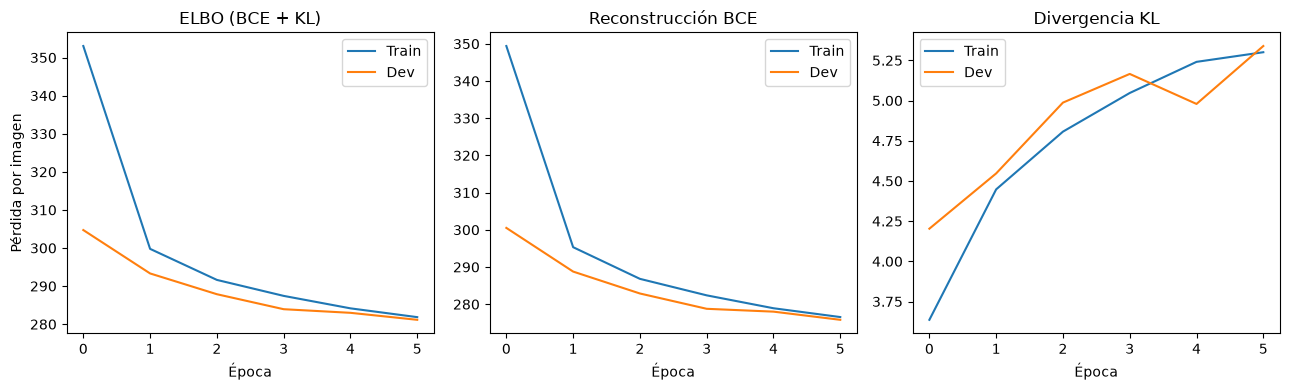

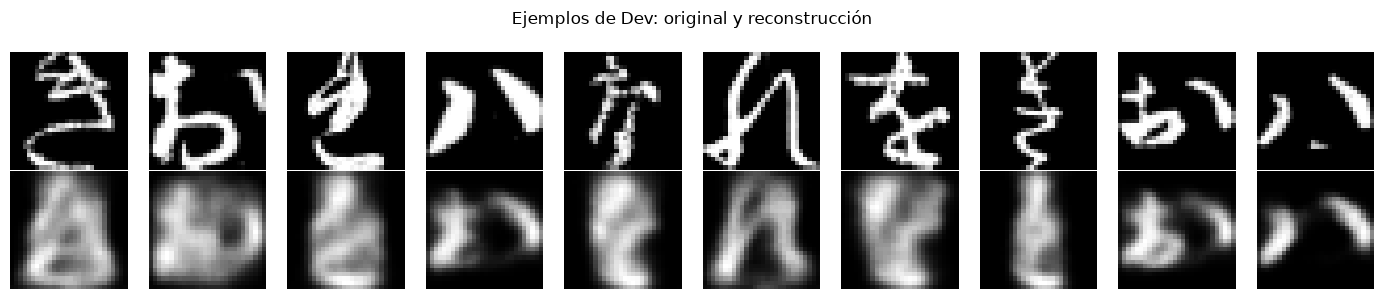

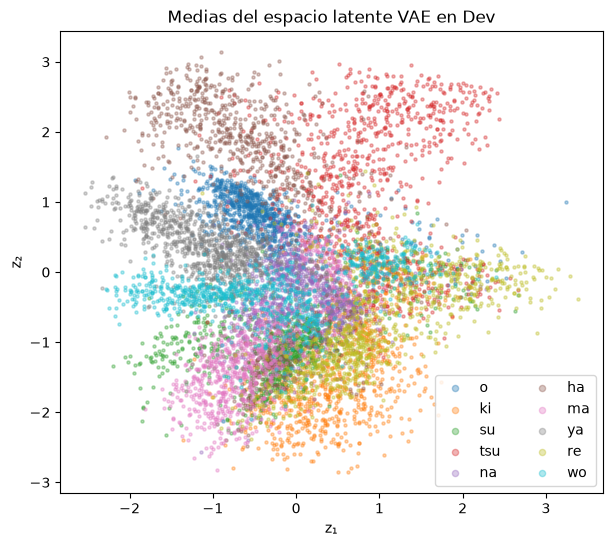

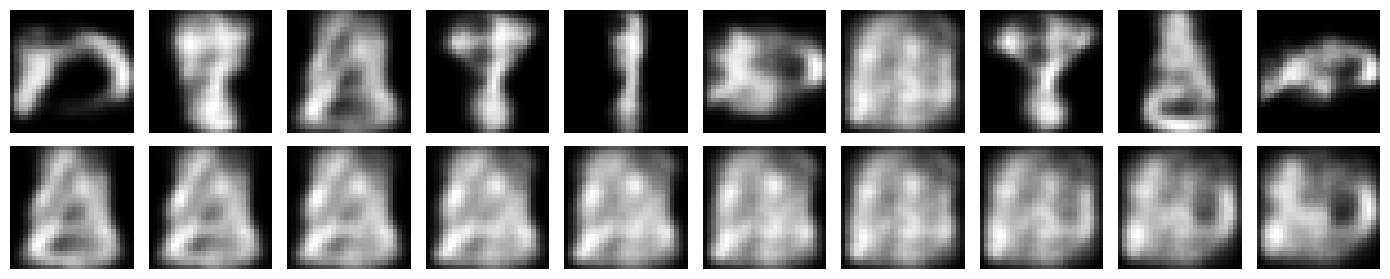

In [13]:
LATENT_DIM = 2

class ConvVAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1), nn.ReLU(),
            nn.Flatten(),
        )
        self.mu = nn.Linear(128 * 7 * 7, latent_dim)
        self.logvar = nn.Linear(128 * 7 * 7, latent_dim)
        self.decoder_input = nn.Linear(latent_dim, 128 * 7 * 7)
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (128, 7, 7)),
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=1, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 1, kernel_size=3, padding=1), nn.Sigmoid(),
        )

    def encode(self, images):
        encoded = self.encoder(images)
        return self.mu(encoded), self.logvar(encoded)

    def decode(self, latent):
        return self.decoder(self.decoder_input(latent))

    def forward(self, images, sample=True):
        mu, logvar = self.encode(images)
        if sample:
            latent = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        else:
            latent = mu
        return self.decode(latent), mu, logvar


def vae_components(model, images, sample):
    reconstruction, mu, logvar = model(images, sample=sample)
    reconstruction_loss = F.binary_cross_entropy(reconstruction, images, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    total = (reconstruction_loss + kl_loss) / len(images)
    return total, reconstruction_loss / len(images), kl_loss / len(images), reconstruction


vae = ConvVAE().to(device)
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
vae_history = {"train_total": [], "dev_total": [], "train_recon": [], "dev_recon": [], "train_kl": [], "dev_kl": [], "dev_mse": []}
vae_start = time.perf_counter()
for epoch in range(VAE_EPOCHS):
    vae.train()
    train_sums = np.zeros(3, dtype=np.float64)
    seen = 0
    for images, _ in train_loader:
        images = images.to(device)
        vae_optimizer.zero_grad(set_to_none=True)
        total, reconstruction_loss, kl_loss, _ = vae_components(vae, images, sample=True)
        total.backward()
        vae_optimizer.step()
        train_sums += np.array([total.item(), reconstruction_loss.item(), kl_loss.item()]) * len(images)
        seen += len(images)

    vae.train(False)
    dev_sums = np.zeros(3, dtype=np.float64)
    squared_error, dev_seen = 0.0, 0
    with torch.no_grad():
        for images, _ in dev_loader:
            images = images.to(device)
            total, reconstruction_loss, kl_loss, reconstruction = vae_components(vae, images, sample=False)
            dev_sums += np.array([total.item(), reconstruction_loss.item(), kl_loss.item()]) * len(images)
            squared_error += F.mse_loss(reconstruction, images, reduction="sum").item()
            dev_seen += len(images)
    train_means, dev_means = train_sums / seen, dev_sums / dev_seen
    for key, value in zip(("train_total", "train_recon", "train_kl"), train_means):
        vae_history[key].append(float(value))
    for key, value in zip(("dev_total", "dev_recon", "dev_kl"), dev_means):
        vae_history[key].append(float(value))
    vae_history["dev_mse"].append(squared_error / (dev_seen * 28 * 28))
    print(
        f"Época {epoch + 1}/{VAE_EPOCHS} | ELBO train/dev="
        f"{train_means[0]:.1f}/{dev_means[0]:.1f} | MSE Dev={vae_history['dev_mse'][-1]:.4f}"
    )
vae_seconds = time.perf_counter() - vae_start
vae_params = count_parameters(vae)
vae_dev_mse = vae_history["dev_mse"][-1]
print(f"VAE: latente={LATENT_DIM}D | parámetros={vae_params:,} | tiempo={vae_seconds:.1f}s | MSE Dev={vae_dev_mse:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].plot(vae_history["train_total"], label="Train")
axes[0].plot(vae_history["dev_total"], label="Dev")
axes[0].set(title="ELBO (BCE + KL)", xlabel="Época", ylabel="Pérdida por imagen")
axes[0].legend()
axes[1].plot(vae_history["train_recon"], label="Train")
axes[1].plot(vae_history["dev_recon"], label="Dev")
axes[1].set(title="Reconstrucción BCE", xlabel="Época")
axes[1].legend()
axes[2].plot(vae_history["train_kl"], label="Train")
axes[2].plot(vae_history["dev_kl"], label="Dev")
axes[2].set(title="Divergencia KL", xlabel="Época")
axes[2].legend()
plt.tight_layout()
plt.show()

# Reconstrucciones deterministas con z = mu.
vae.eval()
example_images = X_dev_t[:10].to(device)
with torch.no_grad():
    reconstructions, _, _ = vae(example_images, sample=False)
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for index in range(10):
    axes[0, index].imshow(example_images[index, 0].cpu(), cmap="gray")
    axes[1, index].imshow(reconstructions[index, 0].cpu(), cmap="gray")
    axes[0, index].axis("off")
    axes[1, index].axis("off")
axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruida")
plt.suptitle("Ejemplos de Dev: original y reconstrucción")
plt.tight_layout()
plt.show()

# Proyección 2D de las medias posteriores para Dev.
latent_means = []
vae.eval()
with torch.no_grad():
    for images, _ in dev_loader:
        means, _ = vae.encode(images.to(device))
        latent_means.append(means.cpu().numpy())
latent_means = np.concatenate(latent_means)
fig, axis = plt.subplots(figsize=(7, 6))
for class_id, class_name in enumerate(class_names):
    mask = y_dev == class_id
    axis.scatter(latent_means[mask, 0], latent_means[mask, 1], s=5, alpha=0.35, label=class_name)
axis.set(title="Medias del espacio latente VAE en Dev", xlabel="z₁", ylabel="z₂")
axis.legend(markerscale=2, ncol=2)
plt.show()

# Muestras del prior y una interpolación entre dos ejemplos de Dev.
with torch.no_grad():
    prior_samples = vae.decode(torch.randn(10, LATENT_DIM, device=device)).cpu()
    endpoint_means, _ = vae.encode(X_dev_t[[0, 1]].to(device))
    interpolation = torch.stack([
        (1 - alpha) * endpoint_means[0] + alpha * endpoint_means[1]
        for alpha in torch.linspace(0, 1, 10, device=device)
    ])
    interpolated_images = vae.decode(interpolation).cpu()
fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for index in range(10):
    axes[0, index].imshow(prior_samples[index, 0], cmap="gray")
    axes[1, index].imshow(interpolated_images[index, 0], cmap="gray")
    axes[0, index].axis("off")
    axes[1, index].axis("off")
axes[0, 0].set_ylabel("Prior")
axes[1, 0].set_ylabel("Interpolación")
plt.tight_layout()
plt.show()

In [16]:
def test_model_and_data_contracts():
    probe_images = X_dev_t[:4].to(device)
    for model in (mlp_reg, cnn):
        model.eval()
        with torch.no_grad():
            logits = model(probe_images)
        assert logits.shape == (4, 10)
        assert torch.isfinite(logits).all()

    vae.eval()
    with torch.no_grad():
        reconstruction, mean, log_variance = vae(probe_images, sample=False)
    assert reconstruction.shape == probe_images.shape
    assert mean.shape == (4, LATENT_DIM)
    assert log_variance.shape == (4, LATENT_DIM)
    assert torch.isfinite(reconstruction).all()
    assert len(error_review) >= 50
    assert len(train_idx) + len(dev_idx) == len(y_all)
    assert set(train_idx).isdisjoint(set(dev_idx))
    print("Pruebas OK: MLP/CNN (4, 10), VAE (4, 1, 28, 28), latente (4, 2), split disjunto y ≥50 errores.")


test_model_and_data_contracts()

Pruebas OK: MLP/CNN (4, 10), VAE (4, 1, 28, 28), latente (4, 2), split disjunto y ≥50 errores.


# 5. Visualizar resultados y cierre
## Etapa 5: comparación, evaluación final y análisis ético

La decisión de modelo se toma exclusivamente con F1-macro en Dev. Recién ahora se carga el conjunto oficial Test, se realiza una sola inferencia del modelo seleccionado y se derivan de esas mismas predicciones todas las métricas y gráficos finales. El VAE se compara por reconstrucción en Dev; no es un clasificador.

Modelo seleccionado por Dev F1-macro: CNN congelada + LogisticRegression (0.9349).
Evaluación final única en Test | F1-macro=0.8464 | accuracy=0.8459
Dev vs Test | F1-macro: 0.9349 vs 0.8464 | accuracy: 0.9348 vs 0.8459


,modelo,arquitectura,parámetros,dev_f1_macro,dev_accuracy,test_f1_macro,test_accuracy,dev_mse_recon,tiempo_seg
6,CNN congelada + LogisticRegression,CNN extractor 128-D congelado + softmax lineal,95252,0.934867,0.934778,0.84637,0.8459,NaN,55.978984
4,CNN congelada + LogisticRegression,CNN extractor 128-D congelado + softmax lineal,95252,0.929379,0.929333,NaN,NaN,NaN,56.314547
2,MLP Dropout + L2 + Early Stopping,784 → 256 → 128 → 64 → 10,242762,0.928413,0.928444,NaN,NaN,NaN,3.446339
1,MLP sin regularización,784 → 256 → 128 → 64 → 10,242762,0.921508,0.921333,NaN,NaN,NaN,2.784784
5,CNN end-to-end,3 bloques Conv/ReLU/MaxPool + clasificador lineal,93962,0.899880,0.899222,NaN,NaN,NaN,51.805071
3,CNN end-to-end,3 bloques Conv/ReLU/MaxPool + clasificador lineal,93962,0.890208,0.890111,NaN,NaN,NaN,51.597062
0,Regresión logística,784 entradas → 10 clases (softmax),7850,0.817121,0.816556,NaN,NaN,NaN,13.187095
7,VAE convolucional,Conv encoder/decoder; z=2D,266085,NaN,NaN,NaN,NaN,0.082939,34.705579


Reporte por clase del modelo seleccionado en Test:
              precision    recall  f1-score   support

           o     0.9091    0.9000    0.9045      1000
          ki     0.8743    0.8350    0.8542      1000
          su     0.7294    0.8250    0.7743      1000
         tsu     0.8350    0.8960    0.8644      1000
          na     0.7998    0.8510    0.8246      1000
          ha     0.8958    0.7820    0.8350      1000
          ma     0.8231    0.8700    0.8459      1000
          ya     0.8993    0.8040    0.8490      1000
          re     0.8422    0.8220    0.8320      1000
          wo     0.8855    0.8740    0.8797      1000

    accuracy                         0.8459     10000
   macro avg     0.8494    0.8459    0.8464     10000
weighted avg     0.8494    0.8459    0.8464     10000



,clase,Dev_recall,Test_recall
0,o,0.962222,0.900
1,ki,0.933333,0.835
2,su,0.910000,0.825
3,tsu,0.938889,0.896
4,na,0.913333,0.851
5,ha,0.927778,0.782
6,ma,0.918889,0.870
7,ya,0.964444,0.804
8,re,0.942222,0.822
9,wo,0.936667,0.874


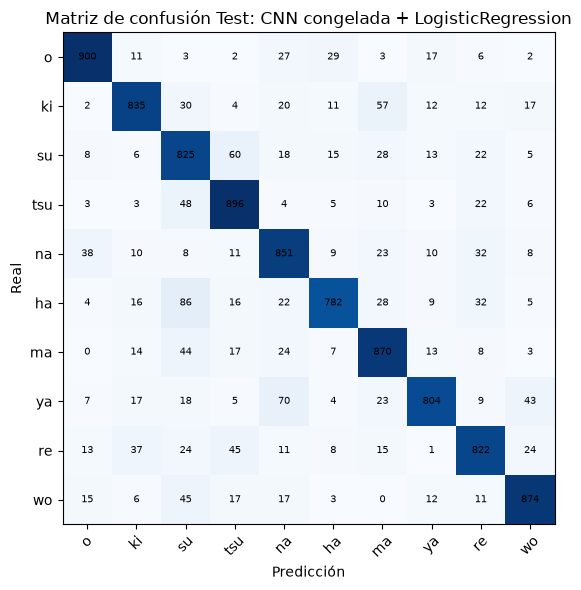

Hay una brecha Dev-Test apreciable; revisar sensibilidad a la partición y posible sobreajuste al proceso de selección en Dev.


In [14]:
# VAE: métrica propia de reconstrucción, no de clasificación.
results.append({
    "modelo": "VAE convolucional",
    "arquitectura": f"Conv encoder/decoder; z={LATENT_DIM}D",
    "parámetros": vae_params,
    "dev_f1_macro": np.nan,
    "dev_accuracy": np.nan,
    "test_f1_macro": np.nan,
    "test_accuracy": np.nan,
    "tiempo_seg": vae_seconds,
    "dev_mse_recon": vae_dev_mse,
})

classifier_models = {
    "Regresión logística": baseline,
    "MLP sin regularización": mlp_plain,
    "MLP Dropout + L2 + Early Stopping": mlp_reg,
    "CNN end-to-end": cnn,
    "CNN congelada + LogisticRegression": pipeline_classifier,
}
best_row = max(
    (row for row in results if row["modelo"] in classifier_models),
    key=lambda row: row["dev_f1_macro"],
)
best_name = best_row["modelo"]
print(f"Modelo seleccionado por Dev F1-macro: {best_name} ({best_row['dev_f1_macro']:.4f}).")

# Predicciones Dev del seleccionado para comparar por clase; no se consultó Test.
if best_name == "Regresión logística":
    selected_dev_pred = baseline.predict(X_dev_flat)
elif best_name == "CNN congelada + LogisticRegression":
    selected_dev_pred = pipeline_classifier.predict(dev_features_scaled)
else:
    selected_model = classifier_models[best_name]
    selected_model.eval()
    selected_predictions = []
    with torch.no_grad():
        for images, _ in dev_loader:
            selected_predictions.append(selected_model(images.to(device)).argmax(dim=1).cpu().numpy())
    selected_dev_pred = np.concatenate(selected_predictions)

dev_report = classification_report(y_dev, selected_dev_pred, output_dict=True, zero_division=0)

# Primera y única carga/iteración evaluativa del split oficial Test.
official_test = datasets.KMNIST(root=DATA_DIR, train=False, download=True)
X_test = official_test.data.numpy()
y_test = official_test.targets.numpy()
X_test_t = torch.from_numpy(X_test.copy()).float().unsqueeze(1).div_(255)
y_test_t = torch.from_numpy(y_test.copy()).long()

if best_name == "Regresión logística":
    test_pred = baseline.predict(X_test.reshape(len(X_test), -1).astype(np.float32) / 255.0)
elif best_name == "CNN congelada + LogisticRegression":
    test_features = extract_cnn_features(cnn, X_test_t, y_test_t)
    test_pred = pipeline_classifier.predict(pipeline_scaler.transform(test_features))
else:
    selected_model = classifier_models[best_name]
    selected_model.eval()
    test_prediction_batches = []
    test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=512, shuffle=False)
    with torch.no_grad():
        for images, _ in test_loader:
            test_prediction_batches.append(selected_model(images.to(device)).argmax(dim=1).cpu().numpy())
    test_pred = np.concatenate(test_prediction_batches)

test_f1 = f1_score(y_test, test_pred, average="macro")
test_accuracy = accuracy_score(y_test, test_pred)
best_row["test_f1_macro"] = test_f1
best_row["test_accuracy"] = test_accuracy
for row in results:
    row.setdefault("test_accuracy", np.nan)
    row.setdefault("dev_mse_recon", np.nan)
    if row["modelo"] == "CNN congelada + LogisticRegression":
        row["tiempo_seg"] += cnn_seconds  # incluye el entrenamiento del extractor.

print(f"Evaluación final única en Test | F1-macro={test_f1:.4f} | accuracy={test_accuracy:.4f}")
print(f"Dev vs Test | F1-macro: {best_row['dev_f1_macro']:.4f} vs {test_f1:.4f} | accuracy: {best_row['dev_accuracy']:.4f} vs {test_accuracy:.4f}")
comparison_table = pd.DataFrame(results)[[
    "modelo", "arquitectura", "parámetros", "dev_f1_macro", "dev_accuracy",
    "test_f1_macro", "test_accuracy", "dev_mse_recon", "tiempo_seg",
]]
display(comparison_table.sort_values("dev_f1_macro", ascending=False, na_position="last"))

print("Reporte por clase del modelo seleccionado en Test:")
print(classification_report(y_test, test_pred, target_names=class_names, digits=4, zero_division=0))
per_class_rows = []
for class_id, class_name in enumerate(class_names):
    key = str(class_id)
    per_class_rows.append({
        "clase": class_name,
        "Dev_recall": dev_report[key]["recall"],
        "Test_recall": classification_report(y_test, test_pred, output_dict=True, zero_division=0)[key]["recall"],
    })
per_class = pd.DataFrame(per_class_rows)
display(per_class)

fig, axis = plt.subplots(figsize=(8, 6))
Confusion = confusion_matrix(y_test, test_pred, labels=np.arange(10))
axis.imshow(Confusion, cmap="Blues")
axis.set(title=f"Matriz de confusión Test: {best_name}", xlabel="Predicción", ylabel="Real")
axis.set_xticks(np.arange(10), class_names, rotation=45)
axis.set_yticks(np.arange(10), class_names)
for row_index in range(10):
    for column_index in range(10):
        axis.text(column_index, row_index, Confusion[row_index, column_index], ha="center", va="center", fontsize=7)
plt.tight_layout()
plt.show()

f1_gap = best_row["dev_f1_macro"] - test_f1
if f1_gap > 0.03:
    print("Hay una brecha Dev-Test apreciable; revisar sensibilidad a la partición y posible sobreajuste al proceso de selección en Dev.")
else:
    print("La brecha Dev-Test es pequeña; no hay evidencia fuerte de sobreajuste a Dev en esta comparación, aunque una sola partición no prueba equivalencia.")

In [15]:
# Consolidar la tabla por nombre de modelo; conserva el registro más reciente si una celda se reejecutó.
results_by_name = {row["modelo"]: row for row in results}
results_clean = list(results_by_name.values())
comparison_table = pd.DataFrame(results_clean)[[
    "modelo", "arquitectura", "parámetros", "dev_f1_macro", "dev_accuracy",
    "test_f1_macro", "test_accuracy", "dev_mse_recon", "tiempo_seg",
]]
assert comparison_table["modelo"].is_unique
assert comparison_table["test_f1_macro"].notna().sum() == 1
assert len(test_pred) == len(y_test)
display(comparison_table.sort_values("dev_f1_macro", ascending=False, na_position="last"))
print("Tabla consolidada: un registro por modelo y un único resultado Test ya calculado.")

,modelo,arquitectura,parámetros,dev_f1_macro,dev_accuracy,test_f1_macro,test_accuracy,dev_mse_recon,tiempo_seg
4,CNN congelada + LogisticRegression,CNN extractor 128-D congelado + softmax lineal,95252,0.934867,0.934778,0.84637,0.8459,NaN,55.978984
2,MLP Dropout + L2 + Early Stopping,784 → 256 → 128 → 64 → 10,242762,0.928413,0.928444,NaN,NaN,NaN,3.446339
1,MLP sin regularización,784 → 256 → 128 → 64 → 10,242762,0.921508,0.921333,NaN,NaN,NaN,2.784784
3,CNN end-to-end,3 bloques Conv/ReLU/MaxPool + clasificador lineal,93962,0.899880,0.899222,NaN,NaN,NaN,51.805071
0,Regresión logística,784 entradas → 10 clases (softmax),7850,0.817121,0.816556,NaN,NaN,NaN,13.187095
5,VAE convolucional,Conv encoder/decoder; z=2D,266085,NaN,NaN,NaN,NaN,0.082939,34.705579


Tabla consolidada: un registro por modelo y un único resultado Test ya calculado.


### Análisis ético, limitaciones y conclusiones

KMNIST contiene etiquetas de caracteres, no atributos de género, etnia, edad o clase social. Por eso, no corresponde presentar diferencias por esos grupos como si el dataset las midiera; la comparación observable es por clase de carácter. En esta ejecución, `ha` y `ya` muestran menor recall en Test que otras clases. Además, las clases están balanceadas en la partición, así que el balance no elimina diferencias de dificultad visual.

Un sistema que lea manuscritos históricos podría transcribir mal nombres, documentos o textos de valor cultural, y las formas históricas no necesariamente representan la escritura contemporánea. No debería usarse como autoridad sin revisión humana. Mitigaciones: publicar el alcance y procedencia del dataset, medir por clase y por colecciones externas, calibrar la confianza, permitir abstención, conservar la imagen fuente y derivar casos dudosos a especialistas en japonés histórico.

**Lectura de resultados de esta corrida:** la regresión logística alcanzó F1-macro 0,8171 en Dev; la MLP regularizada, 0,9284; el pipeline CNN congelada + clasificador, 0,9349 en Dev y 0,8464 en la única evaluación de Test. La caída de aproximadamente 0,0885 puntos entre Dev y Test es importante: sugiere generalización débil o sensibilidad a la selección en Dev, y debe investigarse antes de cualquier uso. La CNN end-to-end obtuvo 0,8999 en Dev. El VAE alcanzó MSE 0,0829 en Dev, una medida de reconstrucción, no comparable con F1 de clasificación.

La MLP regularizada ofrece una relación favorable entre tiempo y rendimiento en Dev; el pipeline es más costoso y su resultado de Test alerta que la mejor puntuación Dev no garantiza mejor generalización. Las redes neuronales se entrenaron con un subconjunto configurable de 15 000 imágenes por viabilidad en CPU; el baseline usó todo el train oficial. Esto limita la comparación estricta entre arquitecturas.

**Mejoras futuras:** repetir la selección con validación cruzada estratificada dentro de train, entrenar las redes con más datos y épocas, controlar sistemáticamente aumentación/regularización y validar en colecciones de otros estilos o fuentes. No volver a ajustar decisiones tras observar este Test; cualquier nueva iteración debería reservar un conjunto de evaluación independiente.